# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [ ]:
# Inspect the shapes of the datasets

import matplotlib.pyplot as plt
import numpy as np



print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)


# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)



print(y_train.shape)   
print(y_test.shape)    
print(y_train[0])      





(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)
(60000, 10)
(10000, 10)
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


"target_class = 9  \n\nrandom_indices = np.random.choice(np.where(y_train == target_class)[0], 9, replace=False)\n\nfig, axes = plt.subplots(3, 3, figsize=(6, 6))\n\nfor i, ax in enumerate(axes.flat):\n    ax.imshow(X_train[random_indices[i]], cmap=plt.cm.gray_r, interpolation='nearest')\n    ax.set_title(class_names[y_train[random_indices[i]]])\n    ax.set_xticks([])\n    ax.set_yticks([])\n\nplt.tight_layout()   # stops the titles overlapping, longer names here\nplt.show()\n# Convert labels to one-hot encoding\nfrom tensorflow.keras.utils import to_categorical\n"

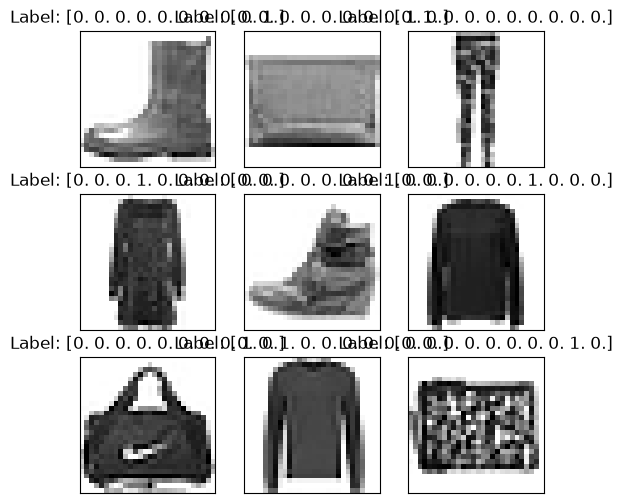

In [22]:
import matplotlib.pyplot as plt
# Verify the data looks as expected


# Selecting 9 random indices
random_indices = np.random.choice(len(X_train), 9, replace=False)

# Creating a 3x3 grid plot
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[random_indices[i]], cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f"Label: {y_train[random_indices[i]]}")

    # Removing axis labels
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()



Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**Your answer here**

Yes we are seeing random samples of the data. The image quality is poor - blurry.

Issues:

- You could have wrong classification since the images are blurry. An ankle boot may be mistaken for a sneaker
- A pullover could be confused with a T-Shirt
- A coat coudl be confused wtih a T-Shirt/Top

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [28]:
from keras.models import Sequential
from keras.layers import Dense, Flatten, Input

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model
model.add(Input(shape=(28, 28  )))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.summary()

# Compile the model using `model.compile()`
model.compile(
    loss='categorical_crossentropy', # Loss function
    optimizer='sgd', # Optimizer
    metrics=['accuracy'] # Metrics to evaluate the model
)

# Train the model with `model.fit()`

model.fit(
    X_train, # Training data
    y_train, # Training labels
    epochs=5, # Number of epochs
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)

# Evaluate the model with `model.evaluate()`

loss, accuracy = model.evaluate(X_test, y_test)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 431us/step - accuracy: 0.7298 - loss: 0.8303 - val_accuracy: 0.8024 - val_loss: 0.5871
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 419us/step - accuracy: 0.8170 - loss: 0.5432 - val_accuracy: 0.8192 - val_loss: 0.5219
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 415us/step - accuracy: 0.8328 - loss: 0.4907 - val_accuracy: 0.8321 - val_loss: 0.4779
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 385us/step - accuracy: 0.8400 - loss: 0.4625 - val_accuracy: 0.8368 - val_loss: 0.4679
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 431us/step - accuracy: 0.8459 - loss: 0.4444 - val_accuracy: 0.8432 - val_loss: 0.4471
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 286us/step - accuracy: 0.8307 - loss: 0.4690
Loss:     0.47
Accuracy: 83.07%


Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Your answer here**

Its hard to give the performance rating since this is the baseline. its 83% which isnt bad but there is room for improvement. This is a baseline and a reference point. Its better than being 70% or lower. This means it could be
actually learning. Further testing is required of course. We need to train the model more.



# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [ ]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()

# We have to add the Conv2D for convolutional layer
# We add the dense using softmax for the one connected layer to make predictions

model.add(Input(shape=(28, 28, 1)))           
model.add(Conv2D(32, (3, 3), activation='relu'))  
model.add(Flatten())                           
model.add(Dense(10, activation='softmax'))     

model.summary()

model.compile(
    loss='categorical_crossentropy', # Loss function
    optimizer='sgd', # Optimizer
    metrics=['accuracy'] # Metrics to evaluate the model
)
# Train the model

model.fit(
    X_train, # Training data
    y_train, # Training labels
    epochs=5, # Number of epochs
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)


# Evaluate the model

loss, accuracy = model.evaluate(X_test, y_test)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 21632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │       216,330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 216,650 (846.29 KB)

 Trainable params: 216,650 (846.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7689 - loss: 0.6728 - val_accuracy: 0.7905 - val_loss: 0.5802
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8242 - loss: 0.4997 - val_accuracy: 0.8401 - val_loss: 0.4624
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8429 - loss: 0.4543 - val_accuracy: 0.8502 - val_loss: 0.4251
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8543 - loss: 0.4209 - val_accuracy: 0.8295 - val_loss: 0.4684
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8630 - loss: 0.3971 - val_accuracy: 0.8664 - val_loss: 0.3896
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 591us/step - accuracy: 0.8561 - loss: 0.4105
Loss:     0.41
Accuracy: 85.61%


Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Your answer here**

It performed somewhat better - very marginal. Only a couple of percent with a little less loss.

Adding the Conv2D gives the conv layer and gives a detection mechanism for the existing picture.

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [48]:
# A. Test Hyperparameters

import tensorflow as tf

for n_filters in [8, 16, 32, 64]:
    tf.keras.utils.set_random_seed(902)

    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(n_filters, (3, 3), activation='relu'))
    model.add(Flatten())
    model.add(Dense(10, activation='softmax'))

    model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2, verbose=0)

    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"{n_filters:3d} filters: accuracy {acc*100:.2f}%, loss {loss:.3f}")


  8 filters: accuracy 84.47%, loss 0.437
 16 filters: accuracy 84.37%, loss 0.440
 32 filters: accuracy 84.51%, loss 0.436
 64 filters: accuracy 84.44%, loss 0.439


In [ ]:
for opt in ['sgd', 'adam']:
    for n_filters in [8, 16, 32, 64]:
        tf.keras.utils.set_random_seed(902)

        model = Sequential()
        model.add(Input(shape=(28, 28, 1)))
        model.add(Conv2D(n_filters, (3, 3), activation='relu'))
        model.add(Flatten())
        model.add(Dense(10, activation='softmax'))

        model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
        model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2, verbose=0)

        loss, acc = model.evaluate(X_test, y_test, verbose=0)
        print(f"{opt:4s} | {n_filters:3d} filters | accuracy {acc*100:.2f}% | loss {loss:.3f}")

sgd  |   8 filters | accuracy 84.84% | loss 0.436
sgd  |  16 filters | accuracy 85.06% | loss 0.430
sgd  |  32 filters | accuracy 85.06% | loss 0.428
sgd  |  64 filters | accuracy 85.24% | loss 0.424
adam |   8 filters | accuracy 88.59% | loss 0.321
adam |  16 filters | accuracy 89.06% | loss 0.309
adam |  32 filters | accuracy 89.28% | loss 0.314
adam |  64 filters | accuracy 89.21% | loss 0.318


In [47]:
# B. Test presence or absence of regularization


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Dropout

for dropout_rate in [0.0, 0.2, 0.5]:
    tf.keras.utils.set_random_seed(902)

    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(32, (3, 3), activation='relu'))
    model.add(Flatten())

    #If dropout_rate is <= 0 then there is no droupout or regularization technique

    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))
    model.add(Dense(10, activation='softmax'))

    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

    history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2, verbose=0)

    #training accuracy
    train_acc = history.history['accuracy'][-1]
    
    #validation accuracy
    val_acc = history.history['val_accuracy'][-1]
    
    loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    print(f"dropout {dropout_rate:.1f} | train {train_acc*100:.2f}% | val {val_acc*100:.2f}% | test {test_acc*100:.2f}% | gap {(train_acc - val_acc)*100:.2f}")

dropout 0.0 | train 96.19% | val 89.39% | test 88.87% | gap 6.80
dropout 0.2 | train 94.78% | val 89.64% | test 89.46% | gap 5.14
dropout 0.5 | train 92.48% | val 89.82% | test 89.34% | gap 2.66


Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Your answer here**

- Iterated through different number of filters. Increasing the number of filters helped as it gives more patterns. You do need to consider that the improvement diminishes. It seemed 32 filters was the sweet spot. The accuracy started to drop at 64.

- I also tried a different optimizer. I compared SGD with Adam. It appears that Adam gives better performance.

- So with this it seemed the combination of 32 filters and Adam gave overall better performance

- For regularization I compared with and without dropout.  The Drop out of 0.5 gave best performance as my Training
was 92.48 and the Test was only 89.34. Validation was good at 89.82. The gap was 2.66. 

- So overall, Filters 32, optimizer Adam and dropout 0.5 gave me the best performance.

- Also note, my research showed that we needed to use the exct same sequence of random numbers. This affected my results

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [52]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dropout, Dense

#This ensures we are using the exact same sequence of random numbers

tf.keras.utils.set_random_seed(902)

#Final Model
#32 filters, Adam optimizer and dropout 0.5


model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

loss, accuracy = model.evaluate(X_test, y_test)
print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8438 - loss: 0.4433 - val_accuracy: 0.8769 - val_loss: 0.3422
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8838 - loss: 0.3258 - val_accuracy: 0.8858 - val_loss: 0.3123
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8957 - loss: 0.2923 - val_accuracy: 0.8925 - val_loss: 0.2993
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9008 - loss: 0.2720 - val_accuracy: 0.8938 - val_loss: 0.2946
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9070 - loss: 0.2588 - val_accuracy: 0.8982 - val_loss: 0.2846
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9109 - loss: 0.2431 - val_accuracy: 0.8974 - val_loss: 0.2886
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9153 - loss: 0.2335 - val_accuracy: 0.8997 - val_loss: 0.2853
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9196 - loss: 0.2225 - 

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Your answer here**

We clearly see an improvement of approx 6.5 points above the baseline. We are very close to 90% as the final test accuracy was 89.34 % The optimizer and dropout really helped along with the filters. The filters gave more patterns - but just enough that it didnt reduce performance. Dropout helps to reduce overfitting and at 0.5 improved performance. Adam gives us better speed vs SGD.

IF I had time I would add more layers - this is a very basic CNN. For example MaxPooling2D could potentially help propel above 90%. In the statement above we noticed that garmets such as Coats, Tops could be confused. adding more layers could help reduce these errors. With an added layer maybe we can distinguish Coat, Pullover, Tops.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.